# Day 5: Pandas Data Analysis

## Project: Online Shopping Sales Analysis

**Objective:** Explore an online shopping dataset using Pandas to understand product categories, prices, quantities, and sales revenue.

**Tools:** Python, Pandas, Jupyter Notebook

**Dataset:** `online_sales.csv`

In [1]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.1.0


In [2]:
df = pd.read_csv("online_sales.csv")

print("Dataset loaded successfully!")
display(df)

Dataset loaded successfully!


,OrderID,Product,Category,Price,Quantity,PaymentMethod,City
0,1001,Wireless Mouse,Electronics,599,2,UPI,Pune
1,1002,Notebook,Stationery,80,5,Cash,Mumbai
2,1003,Headphones,Electronics,1499,1,Card,Delhi
3,1004,Water Bottle,Home,299,3,UPI,Pune
4,1005,Keyboard,Electronics,999,2,Card,Bengaluru
5,1006,Pen Set,Stationery,120,4,Cash,Mumbai
6,1007,Desk Lamp,Home,799,1,UPI,Delhi
7,1008,USB Cable,Electronics,199,5,UPI,Pune
8,1009,Backpack,Accessories,1299,1,Card,Chennai
9,1010,Diary,Stationery,150,3,Cash,Bengaluru


In [3]:
print("First 5 orders:")
display(df.head())

print("Last 5 orders:")
display(df.tail())

First 5 orders:


,OrderID,Product,Category,Price,Quantity,PaymentMethod,City
0,1001,Wireless Mouse,Electronics,599,2,UPI,Pune
1,1002,Notebook,Stationery,80,5,Cash,Mumbai
2,1003,Headphones,Electronics,1499,1,Card,Delhi
3,1004,Water Bottle,Home,299,3,UPI,Pune
4,1005,Keyboard,Electronics,999,2,Card,Bengaluru


Last 5 orders:


,OrderID,Product,Category,Price,Quantity,PaymentMethod,City
20,1021,Table Mat,Home,199,4,Cash,Pune
21,1022,Webcam,Electronics,1899,1,Card,Delhi
22,1023,Marker Set,Stationery,180,3,UPI,Mumbai
23,1024,Travel Pouch,Accessories,499,2,Cash,Chennai
24,1025,Floor Mat,Home,899,1,Card,Bengaluru


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 25
Number of columns: 7
Dataset shape: (25, 7)


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Column names:
['OrderID', 'Product', 'Category', 'Price', 'Quantity', 'PaymentMethod', 'City']

Data types:
OrderID          int64
Product            str
Category           str
Price            int64
Quantity         int64
PaymentMethod      str
City               str
dtype: object


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
OrderID          0
Product          0
Category         0
Price            0
Quantity         0
PaymentMethod    0
City             0
dtype: int64


In [7]:
electronics = df[df["Category"] == "Electronics"]

display(electronics)
print("Number of electronics orders:", len(electronics))

,OrderID,Product,Category,Price,Quantity,PaymentMethod,City
0,1001,Wireless Mouse,Electronics,599,2,UPI,Pune
2,1003,Headphones,Electronics,1499,1,Card,Delhi
4,1005,Keyboard,Electronics,999,2,Card,Bengaluru
7,1008,USB Cable,Electronics,199,5,UPI,Pune
10,1011,Smart Watch,Electronics,2499,2,Card,Mumbai
14,1015,Bluetooth Speaker,Electronics,1799,1,UPI,Bengaluru
18,1019,Power Bank,Electronics,1299,2,Card,Chennai
21,1022,Webcam,Electronics,1899,1,Card,Delhi


Number of electronics orders: 8


In [8]:
expensive_products = df[df["Price"] > 1000]

display(expensive_products)

,OrderID,Product,Category,Price,Quantity,PaymentMethod,City
2,1003,Headphones,Electronics,1499,1,Card,Delhi
8,1009,Backpack,Accessories,1299,1,Card,Chennai
10,1011,Smart Watch,Electronics,2499,2,Card,Mumbai
14,1015,Bluetooth Speaker,Electronics,1799,1,UPI,Bengaluru
18,1019,Power Bank,Electronics,1299,2,Card,Chennai
19,1020,Laptop Bag,Accessories,1099,1,UPI,Bengaluru
21,1022,Webcam,Electronics,1899,1,Card,Delhi


In [9]:
display(df[["Price", "Quantity"]].describe())

,Price,Quantity
count,25.000000,25.000000
mean,762.880000,2.520000
std,654.626822,1.446836
min,60.000000,1.000000
25%,199.000000,1.000000
50%,599.000000,2.000000
75%,1099.000000,3.000000
max,2499.000000,6.000000


In [10]:
df["Revenue"] = df["Price"] * df["Quantity"]

print("Total sales revenue: ₹", df["Revenue"].sum())

display(df[["Product", "Price", "Quantity", "Revenue"]])

Total sales revenue: ₹ 32042


,Product,Price,Quantity,Revenue
0,Wireless Mouse,599,2,1198
1,Notebook,80,5,400
2,Headphones,1499,1,1499
3,Water Bottle,299,3,897
4,Keyboard,999,2,1998
5,Pen Set,120,4,480
6,Desk Lamp,799,1,799
7,USB Cable,199,5,995
8,Backpack,1299,1,1299
9,Diary,150,3,450


In [11]:
top_product = df.loc[df["Revenue"].idxmax()]

print("Top revenue-generating order:")
print("Product:", top_product["Product"])
print("Revenue: ₹", top_product["Revenue"])

Top revenue-generating order:
Product: Smart Watch
Revenue: ₹ 4998


In [12]:
%pip install matplotlib


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:

# Calculate total revenue for each category

category_revenue = df.groupby("Category")["Revenue"].sum()

display(category_revenue)


Category
Accessories     6241
Electronics    16984
Home            5687
Stationery      3130
Name: Revenue, dtype: int64

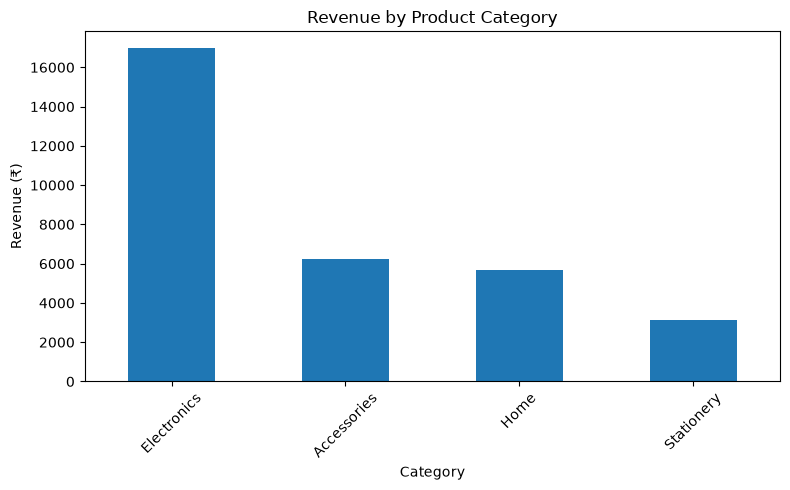

In [14]:

import matplotlib.pyplot as plt

category_revenue = df.groupby("Category")["Revenue"].sum()
category_revenue = category_revenue.sort_values(ascending=False)

category_revenue.plot(
    kind="bar",
    title="Revenue by Product Category",
    xlabel="Category",
    ylabel="Revenue (₹)",
    figsize=(8, 5)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

# Total revenue generated by each product

product_revenue = df.groupby("Product")["Revenue"].sum()
product_revenue = product_revenue.sort_values(ascending=False)

print("Top 5 Products by Revenue:")
display(product_revenue.head(5))


Top 5 Products by Revenue:


Product
Smart Watch          4998
Power Bank           2598
Keyboard             1998
Webcam               1899
Bluetooth Speaker    1799
Name: Revenue, dtype: int64